In [1]:
import pandas as pd 
from matplotlib import pyplot as plt
import seaborn as sns 
dataset = pd.read_csv('/Users/tajveer/Desktop/Niti_DBM_internship/Project_Material/women_entrepreneurship_state_with_gdp_literacy.csv')
df = pd.DataFrame(dataset)

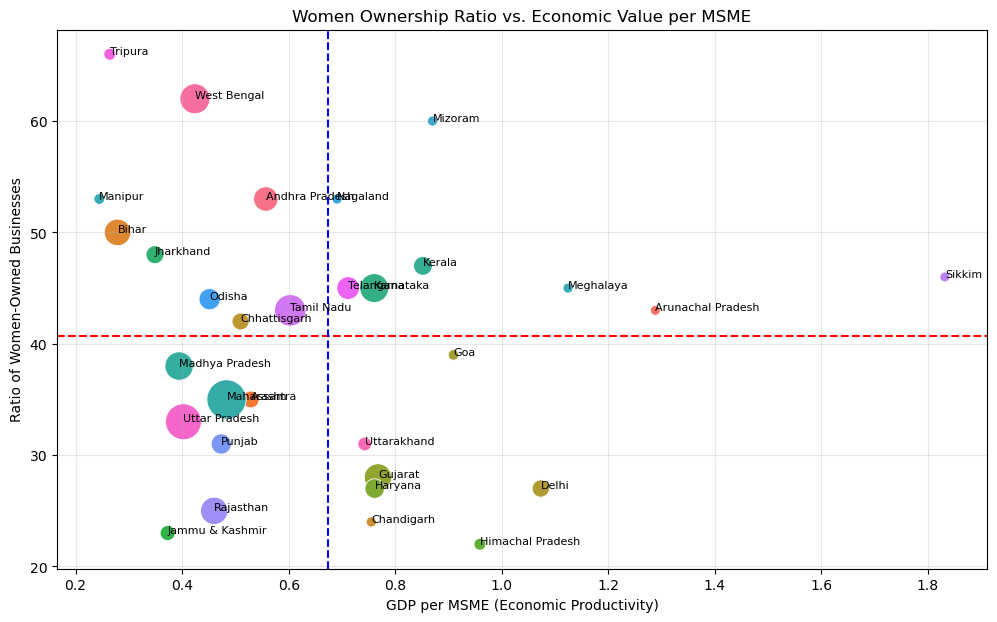

In [16]:
df['GDP_per_MSME'] = df['State_GDP_Crore_INR_2023_24'] / df['Total_MSMEs']
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df, 
    x='GDP_per_MSME', 
    y='Percent_Women_Owned', 
    size='Total_MSMEs',
    hue='State', 
    sizes=(50, 800), 
    legend=False
)

plt.axhline(df['Percent_Women_Owned'].mean(), color='red', linestyle='--', label='Avg Ownership Ratio')
plt.axvline(df['GDP_per_MSME'].mean(), color='blue', linestyle='--', label='Avg GDP per Unit')

for i in range(df.shape[0]):
    plt.text(df.GDP_per_MSME[i], df.Percent_Women_Owned[i], df.State[i], fontsize=8)

plt.title('Women Ownership Ratio vs. Economic Value per MSME')
plt.xlabel('GDP per MSME (Economic Productivity)')
plt.ylabel('Ratio of Women-Owned Businesses')
plt.grid(True, alpha=0.3)
plt.show()

In [52]:


df_sorted = df.sort_values(by='State_GDP_Crore_INR_2023_24', ascending=False)

Top_five_states = df_sorted.head(5)
Bottom_five_states = df_sorted.tail(5)
Bottom_five_states


,State,Total_MSMEs,Women_Owned_MSMEs,Percent_Women_Owned,State_GDP_Crore_INR_2023_24,Literacy_Rate_Percent,GDP_per_MSME
24,Sikkim,21839,10046,46,40000,81.4,1.831586
19,Mizoram,40233,24140,60,35000,91.3,0.869933
1,Arunachal Pradesh,27170,11683,43,35000,66.9,1.288185
20,Nagaland,50675,26858,53,35000,79.6,0.690676
17,Manipur,122764,65068,53,30000,79.9,0.244371


In [57]:
comparison_data = {
    'Metric': [
        'Avg State GDP (Crore INR)',
        'Avg Women Ownership (%)', 
        'Avg Literacy Rate (%)'
    ],
    'Top 5 States (Leaders)': [
        Top_five_states['State_GDP_Crore_INR_2023_24'].mean(),
        Top_five_states['Percent_Women_Owned'].mean(),
        Top_five_states['Literacy_Rate_Percent'].mean()  
    ],
    'Bottom 5 States (Laggards)': [
        Bottom_five_states['State_GDP_Crore_INR_2023_24'].mean(),
        Bottom_five_states['Percent_Women_Owned'].mean(),
        Bottom_five_states['Literacy_Rate_Percent'].mean()
    ]
}

contrast_df = pd.DataFrame(comparison_data)

print("     STRATEGIC CONTRAST ANALYSIS:      ")
print(contrast_df.to_string(index=False))

     STRATEGIC CONTRAST ANALYSIS:      
                   Metric  Top 5 States (Leaders)  Bottom 5 States (Laggards)
Avg State GDP (Crore INR)               2780000.0                    35000.00
  Avg Women Ownership (%)                    36.8                       51.00
    Avg Literacy Rate (%)                    76.7                       79.82


In [59]:
# Regional Mapping Dictionary
region_map = {
    # South
    'Andhra Pradesh': 'South', 'Karnataka': 'South', 'Kerala': 'South', 
    'Tamil Nadu': 'South', 'Telangana': 'South',
    
    # North-East
    'Arunachal Pradesh': 'North-East', 'Assam': 'North-East', 'Manipur': 'North-East', 
    'Meghalaya': 'North-East', 'Mizoram': 'North-East', 'Nagaland': 'North-East', 
    'Sikkim': 'North-East', 'Tripura': 'North-East',
    
    # East
    'Bihar': 'East', 'Jharkhand': 'East', 'Odisha': 'East', 'West Bengal': 'East',
    
    # North
    'Chandigarh': 'North', 'Delhi': 'North', 'Haryana': 'North', 
    'Himachal Pradesh': 'North', 'Jammu & Kashmir': 'North', 
    'Punjab': 'North', 'Rajasthan': 'North', 'Uttarakhand': 'North',
    
    # Central
    'Uttar Pradesh': 'Central', 'Chhattisgarh': 'Central', 'Madhya Pradesh': 'Central',
    
    # West
    'Goa': 'West', 'Gujarat': 'West', 'Maharashtra': 'West'
}

In [68]:
df['Region'] = df['State'].map(region_map)
regional_analysis = df.groupby('Region')['Percent_Women_Owned'].mean().sort_values(ascending=False).reset_index()
regional_analysis

,Region,Percent_Women_Owned
0,East,51.000000
1,North-East,50.125000
2,South,46.600000
3,Central,37.666667
4,West,34.000000
5,North,26.250000


/var/folders/23/m7plmfj94kb8p9ghd1v3b9lh0000gn/T/ipykernel_8966/667407374.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.barplot(data=regional_analysis, x='Region', y='Percent_Women_Owned', palette=palette)


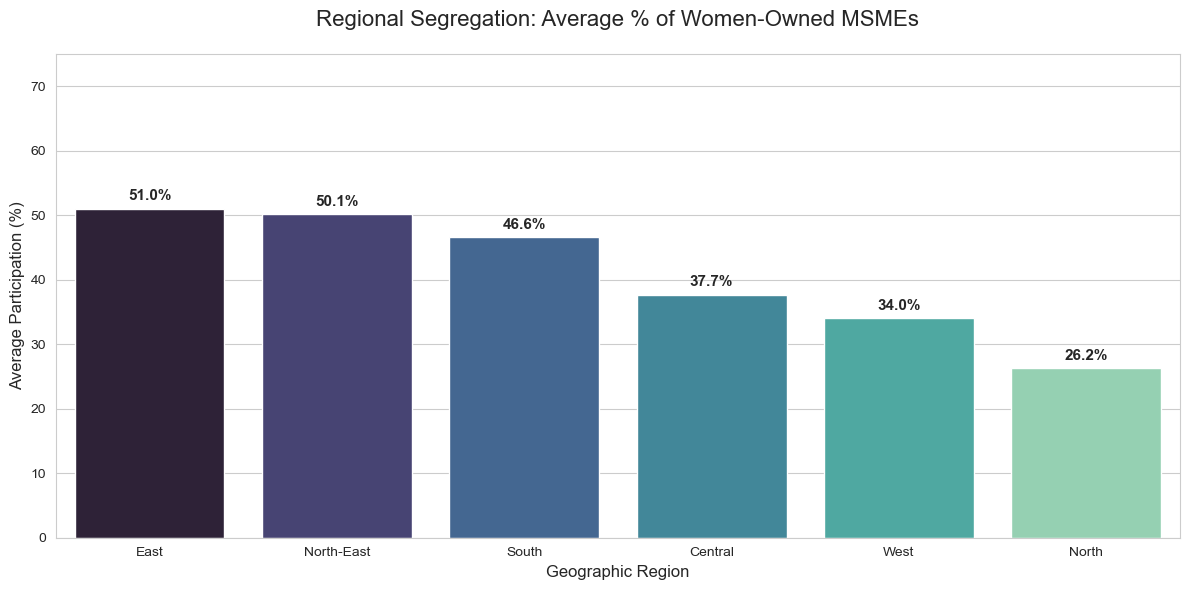

In [77]:
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")
palette = sns.color_palette("mako", len(regional_analysis))
plot = sns.barplot(data=regional_analysis, x='Region', y='Percent_Women_Owned', palette=palette)
for p in plot.patches:
    plot.annotate(format(p.get_height(), '.1f') + '%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points',
                   fontweight='bold', fontsize=11)

plt.title('Regional Segregation: Average % of Women-Owned MSMEs', fontsize=16, pad=20)
plt.ylabel('Average Participation (%)', fontsize=12)
plt.xlabel('Geographic Region', fontsize=12)
plt.ylim(0, 75)
plt.tight_layout()

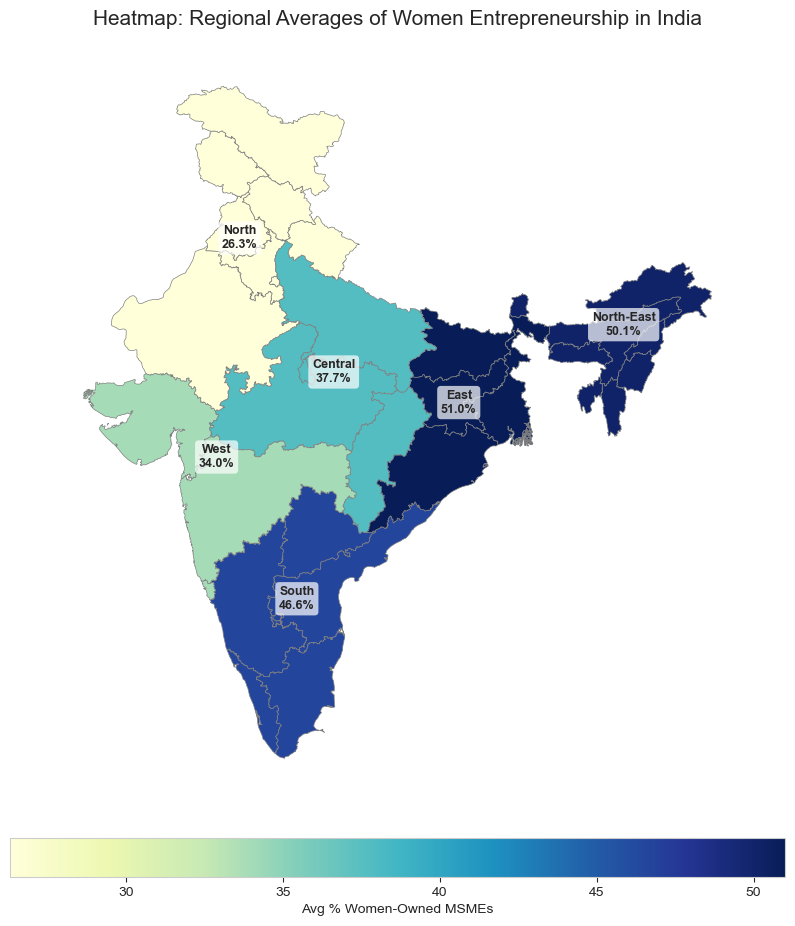

In [112]:

import geopandas as gpd

# 1. Your Data Logic
region_data = {
    'East': 51.0,
    'North-East': 50.1,
    'South': 46.6,
    'Central': 37.7,
    'West': 34.0,
    'North': 26.3
}

# 2. State-to-Region Mapping (Names verified for standard GeoJSONs)
region_map = {
    'Andhra Pradesh': 'South', 'Karnataka': 'South', 'Kerala': 'South', 'Tamil Nadu': 'South', 'Telangana': 'South',
    'Arunachal Pradesh': 'North-East', 'Assam': 'North-East', 'Manipur': 'North-East', 'Meghalaya': 'North-East', 
    'Mizoram': 'North-East', 'Nagaland': 'North-East', 'Sikkim': 'North-East', 'Tripura': 'North-East',
    'Bihar': 'East', 'Jharkhand': 'East', 'Orissa': 'East', 'West Bengal': 'East', 
    'Chandigarh': 'North', 'Delhi': 'North', 'Haryana': 'North', 'Himachal Pradesh': 'North', 
    'Jammu and Kashmir': 'North', 'Punjab': 'North', 'Rajasthan': 'North', 'Uttaranchal': 'North', 
    'Ladakh': 'North', 'Uttar Pradesh': 'Central', 'Chhattisgarh': 'Central', 'Madhya Pradesh': 'Central',
    'Goa': 'West', 'Gujarat': 'West', 'Maharashtra': 'West'
}

# 3. Load the India Map
india_map = gpd.read_file('/Users/tajveer/Downloads/in.json') 

# 4. Merge data with Map
# Using .strip() ensures no hidden spaces break the matching
india_map['name'] = india_map['name'].str.strip()
india_map['Region'] = india_map['name'].map(region_map)
india_map['Avg_Percent'] = india_map['Region'].map(region_data)

# 5. Handle Dissolve (Crucial for regional labels)
regional_boundaries = india_map.dissolve(by='Region')

# 6. Plotting
fig, ax = plt.subplots(1, 1, figsize=(10, 12))

# Plot base map
india_map.plot(column='Avg_Percent', ax=ax, legend=True,
               legend_kwds={'label': "Avg % Women-Owned MSMEs", 
                            'orientation': "horizontal",
                            'pad': 0.05},
               cmap='YlGnBu', edgecolor='0.5', linewidth=0.5)

# 7. Add Labels on Regional Centroids
for idx, row in regional_boundaries.iterrows():
    # Only label if idx (Region name) is not NaN
    if pd.notna(idx):
        centroid = row.geometry.centroid
        percentage = row['Avg_Percent']
        
        ax.text(centroid.x, centroid.y, f"{idx}\n{percentage}%", 
                fontsize=9, fontweight='bold', ha='center', 
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.3'))

plt.title('Heatmap: Regional Averages of Women Entrepreneurship in India', fontsize=15, pad=20)
ax.axis('off')
plt.show()